# Mini-Project 2 — MediCare Outpatient Visits: End-to-End Data Analysis
**Python for Full Stack Data Science with AI & Generative AI · Naresh IT**
*Lead Trainer: Ajit Byru · 3 × 90-minute sessions after Module 15*

**The business problem.** MediCare's hospital administrator has one year of outpatient visit records (`clinic_visits_2025.csv`, ~2,400 visits) and four questions she cannot answer from the billing screen: *Where are patients waiting longest? Which departments actually earn what? Is the clinic getting busier? And what should we change in 2026?*

You are the analyst. **Deliverable:** this notebook, cleaned and complete; a one-paragraph recommendation; a 5-slide summary; a 2-minute pitch.

**Rules:** no `sklearn`, no models — insight, not prediction. Every cleaning decision is written down in the Data-Quality Log. Every question ends in a chart.

| Session | Focus | Sections |
|---|---|---|
| 1 | Load · profile · clean | 1–2 |
| 2 | Five guided questions | 3 |
| 3 | Your own question · recommendation · pitch | 4–6 |

---
## Session 1 — Section 1: Load and profile

Before cleaning anything, *look*. `shape`, `head`, `info`, `describe`, `isna`, `duplicated`, `value_counts` — the profiling checklist from Module 14. Write down every problem you find **before** fixing any of them.

### 1.1 Load
Read the CSV and print its shape and first rows.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("clinic_visits_2025.csv")
print(raw.shape)
raw.head(10)


(2423, 13)


,visit_id,patient_id,visit_date,department,doctor,age,gender,city,wait_minutes,consult_minutes,fee,payment_mode,follow_up
0,V101246,P1873,24/11/2025,Pediatrics,Dr. Das,1,F,Warangal,28,5,560.0,UPI,No
1,V101350,P1692,2025-04-28,Dermatology,Dr. Menon,54,M,Hyderabad,9,29,850.0,Insurance,No
2,V102168,P1159,2025-01-31,General Medicine,Dr. Bose,53,M,Hyderabad,21,20,430.0,UPI,No
3,V101745,P1195,23-Jan-2025,Dermatology,Dr. Menon,79,M,Secunderabad,9,24,900.0,UPI,Yes
4,V101334,P1709,2025-08-25,Orthopedics,Dr. Nair,40,M,Warangal,16,20,940.0,Insurance,Yes
5,V101985,P1304,2025-12-30,ORTHOPEDICS,Dr. Singh,65,F,Hyderabad,18,20,1140.0,UPI,No
6,V100233,P1856,2025-11-12,General Medicine,Dr. Pillai,67,F,Secunderabad,33,23,610.0,UPI,No
7,V100165,P1385,14-May-2025,Dermatology,Dr. Menon,59,M,Secunderabad,10,17,790.0,Insurance,No
8,V102283,P1413,2025-10-31,General Medicine,Dr. Khan,26,M,Secunderabad,30,12,580.0,Cash,Yes
9,V101516,P1693,24-Mar-2025,Pediatrics,Dr. Reddy,1,M,Hyderabad,14,20,530.0,UPI,No


In [3]:
raw.tail(10)  # last rows of the data

,visit_id,patient_id,visit_date,department,doctor,age,gender,city,wait_minutes,consult_minutes,fee,payment_mode,follow_up
2413,V101261,P1029,2025-12-24,General Medicine,Dr. Khan,27,F,Warangal,36,17,590.0,UPI,No
2414,V100689,P1175,11/08/2025,Cardiology,Dr. Iyer,41,M,Warangal,26,16,1310.0,Card,No
2415,V101629,P1423,2025-12-31,Dermatology,Dr. Menon,66,F,Secunderabad,8,21,920.0,UPI,No
2416,V100851,P1003,2025-08-07,Dermatology,Dr. Menon,32,F,Hyderabad,15,20,790.0,Cash,Yes
2417,V100584,P1043,14-Aug-2025,General Medicine,Dr. Bose,56,M,Vijayawada,45,24,430.0,Cash,No
2418,V101698,P1032,15/07/2025,Orthopedics,Dr. Nair,73,F,Secunderabad,5,20,910.0,UPI,No
2419,V100333,P1630,2025-05-26,Pediatrics,Dr. Reddy,12,F,Secunderabad,12,16,610.0,Insurance,No
2420,V101294,P1091,20/03/2025,General Medicine,Dr. Pillai,26,M,Secunderabad,19,16,430.0,Cash,No
2421,V101105,P1418,06-Oct-2025,Orthopedics,Dr. Nair,51,M,Hyderabad,32,19,960.0,UPI,No
2422,V101946,P1025,2025-09-12,General Medicine,Dr. Bose,54,M,Vijayawada,46,26,490.0,UPI,No


### 1.2 `info()` — which columns are the wrong type?
🔮 **PREDICT:** `visit_date` should be a datetime. Will it be?

In [ ]:

raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 2423 entries, 0 to 2422
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   visit_id         2423 non-null   str    
 1   patient_id       2423 non-null   str    
 2   visit_date       2423 non-null   str    
 3   department       2423 non-null   str    
 4   doctor           2423 non-null   str    
 5   age              2423 non-null   int64  
 6   gender           2423 non-null   str    
 7   city             2423 non-null   str    
 8   wait_minutes     2423 non-null   int64  
 9   consult_minutes  2423 non-null   int64  
 10  fee              2303 non-null   float64
 11  payment_mode     2423 non-null   str    
 12  follow_up        2423 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 246.2 KB


### 1.3 `describe()` — anything impossible?
Look at `min` and `max` of every numeric column. A hospital dataset has physical limits.

In [ ]:

raw.describe()


,age,wait_minutes,consult_minutes,fee
count,2423.000000,2423.000000,2423.000000,2303.000000
mean,45.039208,28.637639,17.881965,1076.126791
std,24.484135,11.908123,6.252076,3697.973219
min,0.000000,-37.000000,5.000000,430.000000
25%,27.000000,21.000000,13.000000,560.000000
50%,45.000000,28.000000,18.000000,730.000000
75%,64.000000,37.000000,22.500000,1025.000000
max,412.000000,64.000000,35.000000,50000.000000


### 1.4 Missing values and duplicates

In [ ]:

# Hint: raw.isna().sum() and raw.duplicated().sum()
print("Missing values:")
print(raw.isna().sum())

print("----------------------------")
print("Null Values: ",raw.fee.isna().sum())
print("----------------------------")
print("Duplicate rows:")
print(raw.duplicated().sum())

Missing values:
visit_id             0
patient_id           0
visit_date           0
department           0
doctor               0
age                  0
gender               0
city                 0
wait_minutes         0
consult_minutes      0
fee                120
payment_mode         0
follow_up            0
dtype: int64
----------------------------
Null Values:  120
----------------------------
Duplicate rows:
23


### 1.5 Category hygiene
`value_counts()` on `department`. How many departments does MediCare *actually* have?

In [ ]:

# Hint: raw["department"].value_counts()
print(raw["department"].value_counts())
print("-------------------------------------")
print(raw["payment_mode"].value_counts())
print("-------------------------------------")
print(raw["follow_up"].value_counts())
print("-------------------------------------")
print(raw["doctor"].value_counts())
print("-------------------------------------")
print(raw["gender"].value_counts())
print("-------------------------------------")
print(raw["city"].value_counts())
print("-------------------------------------")
print(raw["age"].value_counts())


department
General Medicine      784
Cardiology            375
Orthopedics           370
Dermatology           311
Pediatrics            302
ENT                   221
general medicine        8
 GENERAL MEDICINE       8
cardiology              8
 DERMATOLOGY            6
ent                     6
orthopedics             5
 ORTHOPEDICS            4
 ENT                    4
 CARDIOLOGY             4
 PEDIATRICS             4
dermatology             3
Name: count, dtype: int64
-------------------------------------
payment_mode
UPI          1038
Cash          665
Card          450
Insurance     270
Name: count, dtype: int64
-------------------------------------
follow_up
No     1553
Yes     870
Name: count, dtype: int64
-------------------------------------
doctor
Dr. Menon     320
Dr. Pillai    277
Dr. Bose      273
Dr. Khan      250
Dr. Joshi     231
Dr. Iyer      201
Dr. Nair      199
Dr. Rao       186
Dr. Singh     180
Dr. Reddy     165
Dr. Das       141
Name: count, dtype: int64
-----

### 1.6 Peek at the dates
Sample a few raw `visit_date` strings. How many different formats can you see?

In [8]:
# Inspect the raw date column.

print(raw["visit_date"].head(20))
print("\nData type:",end=" ")
print(raw["visit_date"].dtype)

0      24/11/2025
1      2025-04-28
2      2025-01-31
3     23-Jan-2025
4      2025-08-25
5      2025-12-30
6      2025-11-12
7     14-May-2025
8      2025-10-31
9     24-Mar-2025
10     2025-02-12
11    06-Aug-2025
12     2025-03-04
13     2025-04-09
14     2025-02-07
15     2025-03-06
16     05/03/2025
17     2025-03-31
18     2025-04-14
19     19/07/2025
Name: visit_date, dtype: str

Data type: str


In [9]:
print("Total rows:", len(raw))
print("Unique dates:", raw["visit_date"].nunique())

Total rows: 2423
Unique dates: 738


In [10]:
# Now let's separate the obvious formats:

dates = raw["visit_date"].astype(str)

print("DD/MM/YYYY:",
      dates.str.match(r"^\d{2}/\d{2}/\d{4}$").sum())


print("YYYY-MM-DD:",
      dates.str.match(r"^\d{4}-\d{2}-\d{2}$").sum())


print("DD-Mon-YYYY:",
      dates.str.match(r"^\d{2}-[A-Za-z]{3}-\d{4}$").sum())

DD/MM/YYYY: 473
YYYY-MM-DD: 1700
DD-Mon-YYYY: 250


In [ ]:

# Hint: raw["visit_date"].sample(8, random_state=1).tolist()
raw["visit_date"].sample(20, random_state=42).tolist()  


['2025-10-04',
 '19/11/2025',
 '25/07/2025',
 '2025-01-31',
 '2025-12-17',
 '2025-09-27',
 '2025-04-14',
 '02/06/2025',
 '17/06/2025',
 '07-May-2025',
 '2025-09-30',
 '2025-08-19',
 '2025-05-14',
 '2025-05-30',
 '2025-06-21',
 '2025-05-09',
 '30/05/2025',
 '2025-05-23',
 '2025-04-01',
 '13-Aug-2025']

### 📝 Data-Quality Log (fill this in — it is graded)
Record every problem found in 1.1–1.6. Add the fix and reasoning as you clean in Section 2.

| # | Problem found | Rows affected | Fix applied | Why this fix (not another) |
|---|---|---:|---|---|
| 1 | Exact duplicate rows | 23 | Removed duplicate rows | Exact duplicates contain no additional information and would double-count visits. |
| 2 | Inconsistent department names/capitalization | 60 | Stripped whitespace and standardized capitalization | These records represent the same departments, so standardization prevents incorrect grouping. |
| 3 | Mixed date formats causing incorrect parsing | 2,423 | Parsed each known date format explicitly | Explicit formats prevent silent day/month swaps, especially for ISO dates. |
| 4 | Impossible ages (≤0 or >110) | 3 | Removed affected rows | The correct age cannot be reliably recovered from the available data. |
| 5 | Negative waiting times | 5 | Converted negative values to absolute values | The negative sign is a data-entry error; the magnitude represents the recorded waiting time. |
| 6 | ₹50,000 fee values flagged as outliers | 13 | Kept the records and added `is_procedure` flag | All 13 values are exactly ₹50,000 and belong to Cardiology/Orthopedics, consistent with procedures. |
| 7 | Missing fees | 120 | Imputed using department-level median | Departments have different typical fees, so a department median preserves group-specific fee patterns better than an overall median or mean. |

---
## Section 2: Clean

Work on a **copy** (`df = raw.drop_duplicates().copy()`) so `raw` stays untouched for comparison. Order matters: duplicates first (so counts are honest), then text, dates, ranges, outliers, and finally imputation.

### 2.1 Duplicates
Drop exact duplicate rows. Print before / after / removed.

In [ ]:

# Hint: df = raw.drop_duplicates().copy()
df= raw.drop_duplicates().copy()
print("Total Rows:",len(df))





Total Rows: 2400


### 2.2 Department names
Strip whitespace and standardise case. Then check the result — did the standardisation break anything?

In [ ]:

# Hint: .str.strip().str.title()  -- then look at the unique values carefully.
df["department"] = df["department"].str.strip().str.title()

df["department"] = df["department"].replace({"Ent": "ENT"})
print(df["department"].value_counts())
df["department"].unique().tolist()

department
General Medicine    792
Cardiology          384
Orthopedics         375
Dermatology         318
Pediatrics          304
ENT                 227
Name: count, dtype: int64


['Pediatrics',
 'Dermatology',
 'General Medicine',
 'Orthopedics',
 'ENT',
 'Cardiology']

### 2.3 Dates — the trap
Three formats live in one column. The tempting one-liner is `pd.to_datetime(..., format="mixed", dayfirst=True)`. Run it and look at the weekday distribution.

🔮 **PREDICT:** MediCare is closed on Sundays. How many Sunday visits should there be?

In [14]:
# [TRAP] The obvious one-liner. Looks fine...
parsed = pd.to_datetime(
    df["visit_date"],
    format="mixed",
    dayfirst=True
)

print(parsed.dtype)
print("Range:", parsed.min().date(), "to", parsed.max().date())
print(parsed.dt.day_name().value_counts())
print("-----------------------------")

print("Sunday visits:", (parsed.dt.day_name() == "Sunday").sum())

datetime64[us]
Range: 2025-01-01 to 2025-12-31
visit_date
Monday       459
Friday       410
Tuesday      408
Wednesday    380
Thursday     355
Saturday     305
Sunday        83
Name: count, dtype: int64
-----------------------------
Sunday visits: 83


> **[TRAP]** 83 Sunday visits at a clinic closed on Sundays. Range looks fine, dtype looks fine — the bug is invisible unless you know a business rule. This is the most important moment in the project.

### 2.4 Investigate
Compare the ISO-formatted strings with what the parser produced.

In [ ]:

# Hint: build a mask for ISO-looking strings with .str.match(r"\d{4}-\d{2}-\d{2}$"); compare parsed.dt.strftime("%Y-%m-%d") with the text

# The clinic is CLOSED on Sundays. 83 Sunday visits means the parser is wrong somewhere.
iso_rows = df["visit_date"].str.match(r"\d{4}-\d{2}-\d{2}$")
iso_text = df.loc[iso_rows, "visit_date"].reset_index(drop=True)
parsed_iso = parsed.reset_index(drop=True)[iso_rows.to_numpy()].reset_index(drop=True)
swapped = parsed_iso.dt.strftime("%Y-%m-%d") != iso_text
print("ISO dates silently day/month-swapped:", swapped.sum(), "of", iso_rows.sum())
print(pd.DataFrame({"text": iso_text[swapped], "parsed": parsed_iso[swapped].dt.date}).head(4))

ISO dates silently day/month-swapped: 596 of 1683
         text      parsed
4  2025-11-12  2025-12-11
6  2025-02-12  2025-12-02
7  2025-03-04  2025-04-03
8  2025-04-09  2025-09-04


> `dayfirst=True` is applied to ISO strings too: `2025-11-12` becomes 11-Dec. Only dates with day ≤ 12 flip, so 596 of 1,683 ISO rows silently moved. **Lesson: never let a parser guess when you know the formats.**

### 2.5 Fix — parse each format explicitly
Write a function that tries each format in turn with `errors="coerce"` and fills gaps. Verify: zero unparsed, zero Sundays.

In [ ]:

# Hint: pd.to_datetime(s, format="%Y-%m-%d", errors="coerce") then .fillna(...) with the next format

df["visit_date_parsed"] = pd.NaT

# YYYY-MM-DD
mask_ymd = df["visit_date"].str.match(
    r"^\d{4}-\d{2}-\d{2}$"
)

df.loc[mask_ymd, "visit_date_parsed"] = pd.to_datetime(
    df.loc[mask_ymd, "visit_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# DD/MM/YYYY
mask_dmy = df["visit_date"].str.match(
    r"^\d{2}/\d{2}/\d{4}$"
)

df.loc[mask_dmy, "visit_date_parsed"] = pd.to_datetime(
    df.loc[mask_dmy, "visit_date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# DD-Mon-YYYY
mask_dmony = df["visit_date"].str.match(
    r"^\d{2}-[A-Za-z]{3}-\d{4}$"
)

df.loc[mask_dmony, "visit_date_parsed"] = pd.to_datetime(
    df.loc[mask_dmony, "visit_date"],
    format="%d-%b-%Y",
    errors="coerce"
)

In [17]:
print("Unparsed dates:",
      df["visit_date_parsed"].isna().sum())

print(
    df["visit_date_parsed"]
    .dt.day_name()
    .value_counts()
    .sort_index()
)

print(
    "Sunday visits:",
    (df["visit_date_parsed"].dt.day_name() == "Sunday").sum()
)

Unparsed dates: 0
visit_date_parsed
Friday       422
Monday       495
Saturday     302
Thursday     376
Tuesday      397
Wednesday    408
Name: count, dtype: int64
Sunday visits: 0


In [18]:
print(
    "Date range:",
    df["visit_date_parsed"].min().date(),
    "to",
    df["visit_date_parsed"].max().date()
)

Date range: 2025-01-01 to 2025-12-31


### 2.6 Impossible ages
Find ages ≤ 0 or > 110. Decide: repair or reject? (There is no way to recover a true age — reject, and record the visit_ids.)

In [ ]:

# Hint: (df["age"] <= 0) | (df["age"] > 110)
bad_age = (df["age"] <= 0) | (df["age"] > 110)

print("Impossible age rows:", bad_age.sum())

Impossible age rows: 0


In [ ]:
#   Verify-
print("Shape before age cleaning:", df.shape)

print("Remaining impossible ages:")

print(df[(df["age"] <= 0) | (df["age"] > 110)][["visit_id", "age"]])

Shape after age cleaning: (2400, 14)
Remaining impossible ages:
     visit_id  age
1629  V101228    0
2032  V102161  412
2251  V102242  199


In [41]:

df = df.loc[~bad_age].copy()

print("Shape after age cleaning:", df.shape)
print("Remaining impossible ages:", 
      ((df["age"] <= 0) | (df["age"] > 110)).sum())

Shape after age cleaning: (2397, 16)
Remaining impossible ages: 0


### 2.7 Negative wait times
A negative wait is a sign error at data entry, not a real value. Decide: repair (`abs`) or reject? Justify in the log.

In [ ]:

# Hint: df.loc[mask, "wait_minutes"] = ...abs()
negative_wait = df["wait_minutes"] < 0

print("Negative wait rows:", negative_wait.sum())

df.loc[negative_wait, "wait_minutes"] = (
    df.loc[negative_wait, "wait_minutes"].abs()
)

print("Min wait now:", df["wait_minutes"].min())

Negative wait rows: 5
Min wait now: 3


### 2.8 Fee outliers — the judgement call
Apply the 1.5 × IQR fence from Module 15. Then **look at what it flags** before doing anything.

In [ ]:

# Hint: df["fee"].quantile([0.25, 0.75]); fence = q3 + 1.5*iqr; look at department and unique fee values of flagged rows
q1, q3 = df["fee"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr

flagged = df[df["fee"] > upper]

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, upper limit = {upper}")
print("Rows above limit:", len(flagged))
print(flagged["department"].value_counts())
print(flagged["fee"].unique())

Q1 = 560.0, Q3 = 1030.0, IQR = 470.0, upper limit = 1735.0
Rows above limit: 13
department
Orthopedics    7
Cardiology     6
Name: count, dtype: int64
[50000.]


> **[BEAT]** The fence is right to flag; the analyst is right to keep. Thirteen visits, every one exactly ₹50,000, every one in the two departments that do procedures. Dropping them would erase ₹6.5 lakh of real revenue. Rules find candidates; judgement decides.

### 2.9 Decide
The fence flags them. Are they errors? Look at the values and the departments. Write your decision in the log.

In [ ]:

# Hint: df["is_procedure"] = ...
# consistent with a procedure, not a typo. We add a flag so analysis can include or exclude them deliberately.
# Decision: KEEP. All flagged fees are exactly 50,000 and all sit in Cardiology / Orthopedics — because they cannot be established as errors.
df["is_procedure"] = df["fee"] == 50000
print(df["is_procedure"].sum(), "procedures flagged")

print(df["is_procedure"].value_counts())

13 procedures flagged
is_procedure
False    2384
True       13
Name: count, dtype: int64


In [25]:
fee_summary = (
    df.groupby("is_procedure")["fee"]
      .agg(["mean", "median", "max"])
)

print(fee_summary)

                     mean   median      max
is_procedure                               
False           798.80406    720.0   1500.0
True          50000.00000  50000.0  50000.0


**The Grouped bar chart**

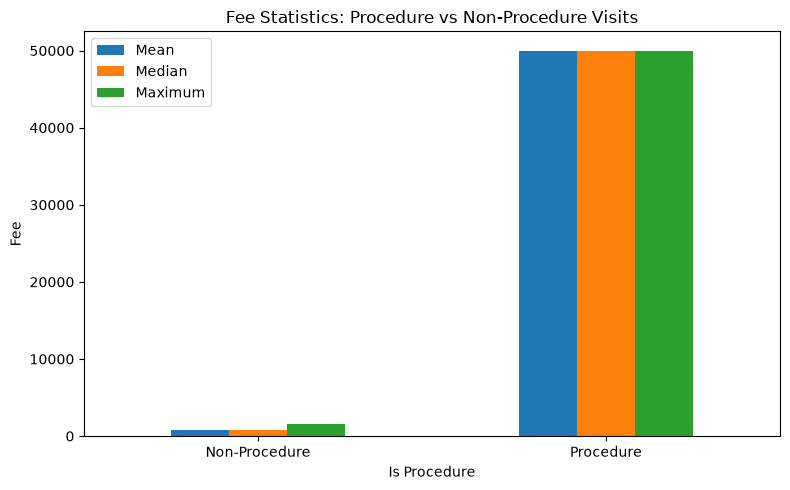

In [ ]:

fee_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fee Statistics: Procedure vs Non-Procedure Visits")
plt.xlabel("Is Procedure")
plt.ylabel("Fee")
plt.xticks(
    [0, 1],
    ["Non-Procedure", "Procedure"],
    rotation=0
)
plt.legend(["Mean", "Median", "Maximum"])
plt.tight_layout()
plt.show()

### 2.10 Missing fees
Impute with a median — but *which* median? 🔮 **PREDICT:** What goes wrong if you use the overall median for a Cardiology visit?

In [ ]:

# Hint: dept_median = df.groupby("department")["fee"].median(); df["department"].map(dept_median)
print("Missing fees before imputation:", df["fee"].isna().sum())

print("-------------------------------------")

department_medians = df.groupby("department")["fee"].median()

print("Department-level median fees:")
print(department_medians)

Missing fees before imputation: 0
-------------------------------------
Department-level median fees:
department
Cardiology          1260.0
Dermatology          850.0
ENT                  740.0
General Medicine     520.0
Orthopedics         1060.0
Pediatrics           630.0
Name: fee, dtype: float64


In [28]:
# Fill missing fees.....

df["fee"] = df["fee"].fillna(
    df.groupby("department")["fee"].transform("median")
)

> Overall median ≈ ₹700. Per-department median ranges ₹520–₹1,260. Imputation must respect the group — the same idea as `groupby`, applied to filling gaps.

In [29]:
# Verify.
print("Missing fees after imputation:", df["fee"].isna().sum())

# verify that the number of rows hasn't changed.
print("Shape:", df.shape)

Missing fees after imputation: 0
Shape: (2397, 15)


In [30]:
print(df.isna().sum())

visit_id             0
patient_id           0
visit_date           0
department           0
doctor               0
age                  0
gender               0
city                 0
wait_minutes         0
consult_minutes      0
fee                  0
payment_mode         0
follow_up            0
visit_date_parsed    0
is_procedure         0
dtype: int64


### 2.11 Derived columns and save
Add `weekday` and `month`. Save `clinic_visits_clean.csv`. Print the final shape — this is your acceptance number.

In [ ]:

# Hint: df["visit_date"].dt.day_name(), .dt.month; df.to_csv("clinic_visits_clean.csv", index=False)
df["visit_date"] = df["visit_date_parsed"]
df["weekday"] = df["visit_date"].dt.day_name()
df["month"] = df["visit_date"].dt.month
df = df.drop(columns=["visit_date_parsed"])
df.to_csv("clinic_visits_clean.csv", index=False)
print("Final shape:", df.shape)
print("Departments:", df["department"].nunique(), "| Doctors:", df["doctor"].nunique(), "| Cities:", df["city"].nunique())

Final shape: (2397, 16)
Departments: 6 | Doctors: 11 | Cities: 5


> **Acceptance numbers:** 2,423 → 2,400 (dedup) → 2,397 (age) rows; 16 columns; 6 departments; 11 doctors; 0 missing fees; 0 Sunday visits; 13 procedures.

---
## Session 2 — Section 3: Five guided questions

Each question ends in a chart with a title, axis labels and a one-sentence reading in the markdown cell below it. **A chart without a sentence is not an answer.**

### Q1. Which department is busiest, and on which weekday?
Two bar charts. Reading: what does Monday mean for staffing?

department
General Medicine    790
Cardiology          383
Orthopedics         375
Dermatology         318
Pediatrics          304
ENT                 227
Name: count, dtype: int64


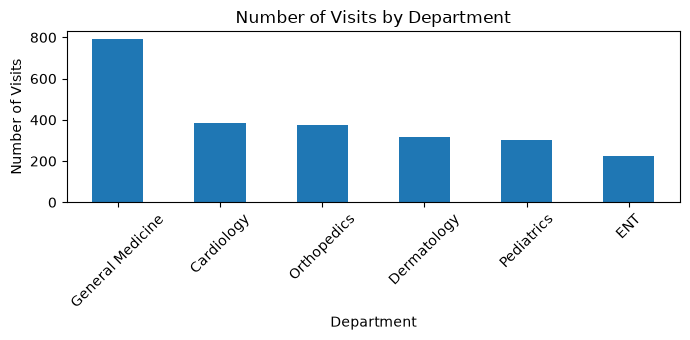

In [ ]:

# Hint: value_counts().plot(kind="bar"); reindex weekdays in order

# Visits by department
department_counts = df["department"].value_counts()
print(department_counts)

plt.figure(figsize=(7, 3.5))
department_counts.plot(kind="bar")

plt.title("Number of Visits by Department")
plt.xlabel("Department")
plt.ylabel("Number of Visits")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

weekday
Monday       495
Tuesday      396
Wednesday    407
Thursday     376
Friday       421
Saturday     302
Sunday         0
Name: count, dtype: int64


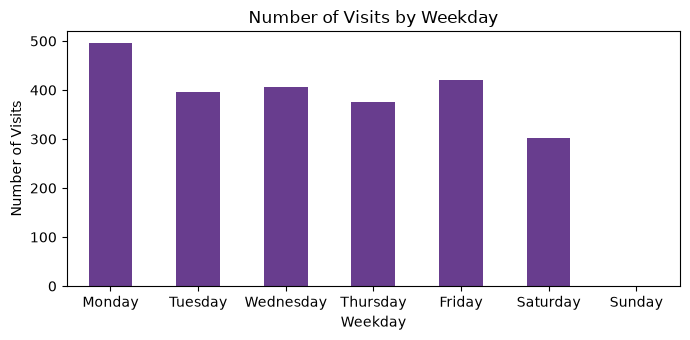

In [33]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_counts = (
    df["weekday"]
    .value_counts()
    .reindex(weekday_order, fill_value=0).astype(int)
)
print(weekday_counts)

plt.figure(figsize=(7, 3.5))
weekday_counts.plot(kind="bar",color="#683D8E")

plt.title("Number of Visits by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Visits")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

> **Reading:** General Medicine has the highest visit volume at 790 visits, while Monday is the busiest weekday with 495 visits, suggesting that staffing capacity should be reviewed particularly at the beginning of the week.

### Q2. Where do patients wait longest?
Group wait time by department: mean, median, std, and the 90th percentile. Box plot. Reading: which department's *worst* days matter most?

                  mean  median  std   p90
department                               
General Medicine  37.8    38.0  8.9  49.0
Cardiology        31.9    32.0  9.0  43.0
Orthopedics       25.9    26.0  8.8  37.0
Pediatrics        22.1    22.5  8.6  32.0
ENT               20.1    19.0  9.0  32.4
Dermatology       18.4    18.0  8.5  29.3


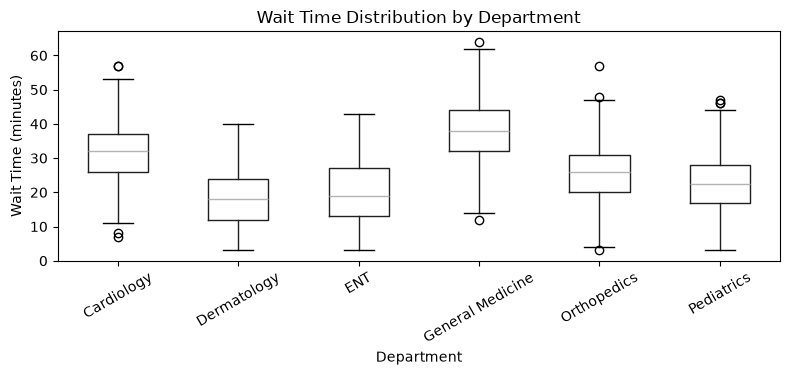

In [ ]:

# Hint: groupby("department")["wait_minutes"].agg(mean=..., median=..., std=..., p90=lambda s: s.quantile(0.9)); df.boxplot(column=..., by=...)

wait_stats = (
    df.groupby("department")["wait_minutes"]
      .agg(
          mean="mean",
          median="median",
          std="std",
          p90=lambda s: s.quantile(0.90))
          .sort_values("mean", ascending=False).round(1) # type: ignore
)

print(wait_stats)

fig, ax = plt.subplots(figsize=(8, 4))

df.boxplot(
    column="wait_minutes",
    by="department",
    grid=False,
    ax=ax
)

ax.set_title("Wait Time Distribution by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Wait Time (minutes)")
ax.tick_params(axis="x", rotation=30)

fig.suptitle("")
fig.tight_layout()
plt.show()



In [80]:
print("\nDepartment with longest average wait:")
print(wait_stats["mean"].idxmax(), "-", wait_stats["mean"].max(), "minutes")

print("\nBusiest department:")
print(df["department"].value_counts().idxmax())


Department with longest average wait:
General Medicine - 37.769620253164554 minutes

Busiest department:
General Medicine


> **Reading:** General Medicine has the longest average wait at 37.8 minutes and a 90th-percentile wait of 49.0 minutes, indicating that both typical and high-end waiting times are relatively high in the busiest department.

### Q3. What does each department really earn per visit?
Mean vs median fee by department, with and without procedures. Reading: which number would you put in the annual report, and why?

In [ ]:

# Hint: agg(mean=..., median=..., max=...) with and without df["is_procedure"]; grouped bar via .plot(kind="bar")

fee_by_department = (
    df.groupby("department")["fee"]
      .agg(["mean", "median"])
      .sort_values("mean", ascending=False).round(0)
)

print(fee_by_department)

fee_without_procedures = (
    df[~df["is_procedure"]]
    .groupby("department")["fee"]
    .agg(["mean", "median"])
    .sort_values("mean", ascending=False).round(0)
)

print(fee_without_procedures)

                    mean  median
department                      
Cardiology        2021.0  1260.0
Orthopedics       1973.0  1060.0
Dermatology        847.0   850.0
ENT                736.0   740.0
Pediatrics         632.0   630.0
General Medicine   522.0   520.0
                    mean  median
department                      
Cardiology        1258.0  1260.0
Orthopedics       1059.0  1060.0
Dermatology        847.0   850.0
ENT                736.0   740.0
Pediatrics         632.0   630.0
General Medicine   522.0   520.0


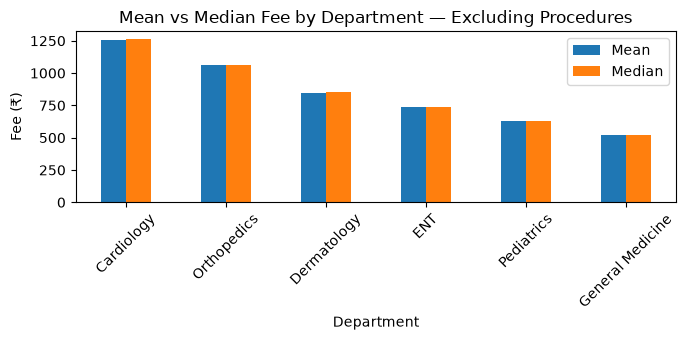

In [82]:
# compare mean vs median without procedures first, because the ₹50,000 procedure fees can heavily distort the mean.
# without procedures..
fee_without_procedures.plot(
    kind="bar",
    figsize=(7, 3.5)
)

plt.title("Mean vs Median Fee by Department — Excluding Procedures")
plt.xlabel("Department")
plt.ylabel("Fee (₹)")
plt.xticks(rotation=45)
plt.legend(["Mean", "Median"])
plt.tight_layout()
plt.show()

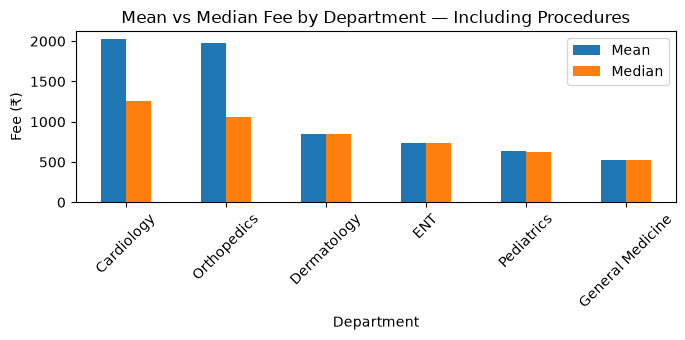

In [83]:
# the effect of procedures.
fee_by_department.plot(
    kind="bar",
    figsize=(7, 3.5)
)

plt.title("Mean vs Median Fee by Department — Including Procedures")
plt.xlabel("Department")
plt.ylabel("Fee (₹)")
plt.xticks(rotation=45)
plt.legend(["Mean", "Median"])
plt.tight_layout()
plt.show()

>Cardiology and Orthopedics show higher fees than the other departments, and the ₹50,000 procedure fees pull their means sharply upward. Reading: median is the better annual-report measure because it represents the typical visit without being distorted by exceptional procedure charges.

### Q4. Does patient age relate to consultation length?
Scatter, `r`, `np.polyfit` line. Reading: how much longer per decade of age?

In [ ]:

# Hint: np.corrcoef(...)[0, 1]; np.polyfit(..., deg=1); plt.scatter + plt.plot

# Age vs consultation time
x = df["age"]
y = df["consult_minutes"]

# Correlation
r = np.corrcoef(x, y)[0, 1]

# Linear fit
slope, intercept = np.polyfit(x, y, 1)

print(f"Correlation (r): {r:.3f}")
print(f"consult_minutes = {slope:.2f} * age + {intercept:.2f}")
print(f"Slope: {slope:.3f} minutes per year")
print(f"Change per decade: {slope * 10:.2f} minutes")
print(f"Intercept: {intercept:.2f}")

Correlation (r): 0.767
consult_minutes = 0.21 * age + 8.56
Slope: 0.208 minutes per year
Change per decade: 2.08 minutes
Intercept: 8.56


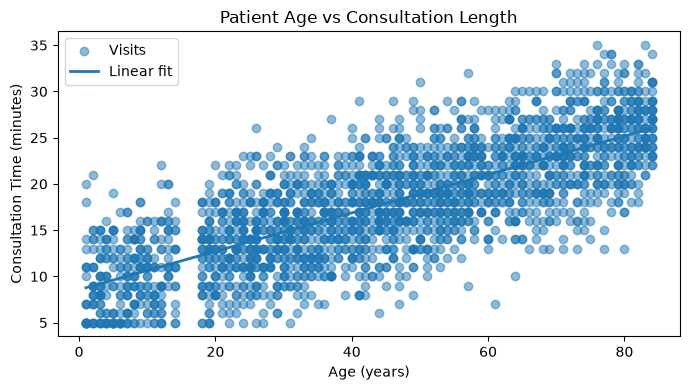

In [85]:
# Create the scatter plot and fitted line..

plt.figure(figsize=(7, 4))

plt.scatter(x, y, alpha=0.5, label="Visits")

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear fit"
)

plt.title("Patient Age vs Consultation Length")
plt.xlabel("Age (years)")
plt.ylabel("Consultation Time (minutes)")
plt.legend()
plt.tight_layout()
plt.show()

> **Reading:** Consultation time increases by approximately 2.08 minutes per decade of age, with a positive correlation of r = 0.767; older patients tend to have longer consultations, although this association does not establish causation.

### Q5. What does the monthly revenue trend tell us about clinic activity?
Line chart, all revenue vs consultations only. Reading: are the spikes growth or single events?

In [ ]:

# Hint: groupby("month")["fee"].sum() / 1e5, twice (all / non-procedure); plt.plot with marker

# Calculate monthly revenue..

# Monthly revenue — all visits
monthly_revenue_all = (
    df.groupby("month")["fee"]
      .sum()
      .sort_index()
      / 1e5
)

# Monthly revenue — consultations only
monthly_revenue_consultations = (
    df[~df["is_procedure"]]
      .groupby("month")["fee"]
      .sum()
      .reindex(range(1, 13), fill_value=0)
      / 1e5
)

print("All visits:")
print(monthly_revenue_all)

print("\nConsultations only:")
print(monthly_revenue_consultations)

All visits:
month
1     3.6213
2     1.8533
3     2.0808
4     2.1126
5     2.5727
6     2.4633
7     1.4575
8     1.8101
9     2.6664
10    1.6614
11    1.4613
12    1.7888
Name: fee, dtype: float64

Consultations only:
month
1     1.6213
2     1.3533
3     1.5808
4     1.6126
5     1.5727
6     1.4633
7     1.4575
8     1.8101
9     1.6664
10    1.6614
11    1.4613
12    1.7888
Name: fee, dtype: float64


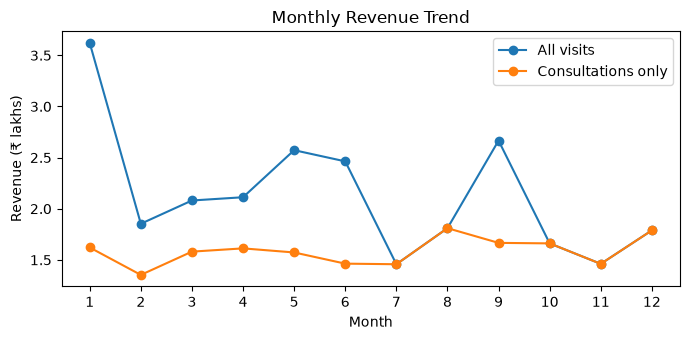

In [87]:
plt.figure(figsize=(7, 3.5))

plt.plot(
    monthly_revenue_all.index.to_numpy(dtype=float),
    monthly_revenue_all.to_numpy(dtype=float),
    marker="o",
    label="All visits"
)

plt.plot(
    monthly_revenue_consultations.index.to_numpy(dtype=float),
    monthly_revenue_consultations.to_numpy(dtype=float),
    marker="o",
    label="Consultations only"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹ lakhs)")
plt.xticks(range(1, 13))
plt.legend()
plt.tight_layout()
plt.show()

In [88]:
# Find the highest and lowest months...
print("Highest all-visit revenue:",
    monthly_revenue_all.idxmax(),
    "- ₹",
    round(monthly_revenue_all.max(), 2),
    "lakhs"
)
print("Lowest all-visit revenue:",
    monthly_revenue_all.idxmin(),
    "- ₹",
    round(monthly_revenue_all.min(), 2),
    "lakhs"
)
print("\nHighest consultation-only revenue:",
    monthly_revenue_consultations.idxmax(),
    "- ₹",
    round(monthly_revenue_consultations.max(), 2),
    "lakhs"
)
print("Lowest consultation-only revenue:",
    monthly_revenue_consultations.idxmin(),
    "- ₹",
    round(monthly_revenue_consultations.min(), 2),
    "lakhs"
)

Highest all-visit revenue: 1 - ₹ 3.62 lakhs
Lowest all-visit revenue: 7 - ₹ 1.46 lakhs

Highest consultation-only revenue: 8 - ₹ 1.81 lakhs
Lowest consultation-only revenue: 2 - ₹ 1.35 lakhs


> **Reading:** All-visit revenue peaks at ₹3.62 lakh in January and falls to ₹1.46 lakh in July, while consultation-only revenue peaks at ₹1.81 lakh in August; the different peak months suggest that revenue spikes are influenced by procedure activity rather than representing consistent growth.

---
## Session 3 — Section 4: Your own question

Pick **one** and take it further than the guided questions did — this is your headline finding and your slide 3.

1. **Doctor workload** — is any doctor carrying an unfair share of visits or wait time within their department?
2. **Follow-up compliance** — Which departments have the highest follow-up rates?
3. **Payment-mode trends** — is UPI displacing cash across the year? Does mode differ by city or age?
4. **City-wise access** — do out-of-city patients wait longer or pay more?
5. **Consultation efficiency** — wait vs consult ratio by department: where does the queue exceed the care?
6. **Revenue concentration** — what share of revenue comes from the top 10% of visits? Top 2 departments?

Requirements: at least one `groupby`, one chart, one statistic you can defend, and a sentence on what you'd need to be sure.

In [52]:
# YOUR CODE HERE
# Own Question: Which departments have the highest follow-up rates?
 
# Use follow-up rate (%) as the defended statistic because departments have different numbers of visits.

print(df["follow_up"].value_counts())
print("----------------------------------")

followup_by_department = (
    df.groupby("department")["follow_up"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

print("Follow-up rate by department:")
print(followup_by_department.round(2))


follow_up
No     1537
Yes     860
Name: count, dtype: int64
----------------------------------
Follow-up rate by department:
department
General Medicine    39.62
Orthopedics         38.93
ENT                 34.36
Cardiology          33.16
Pediatrics          32.24
Dermatology         30.82
Name: follow_up, dtype: float64


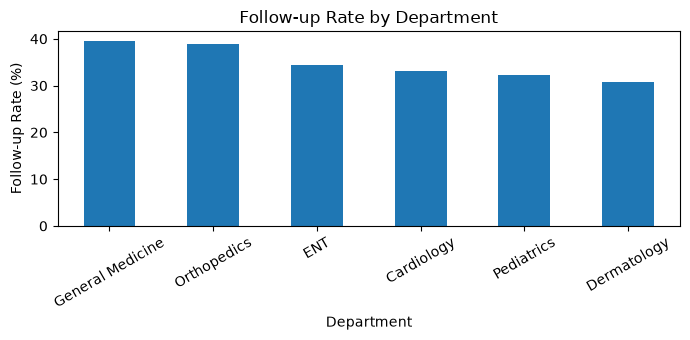

In [55]:
plt.figure(figsize=(7, 3.5))

followup_by_department.plot(kind="bar")

plt.title("Follow-up Rate by Department")
plt.xlabel("Department")
plt.ylabel("Follow-up Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [54]:
# Highest and lowest..

print(
    "Highest follow-up rate:",
    followup_by_department.idxmax(),
    "-",
    round(followup_by_department.max(), 2),
    "%"
)

print(
    "Lowest follow-up rate:",
    followup_by_department.idxmin(),
    "-",
    round(followup_by_department.min(), 2),
    "%"
)

Highest follow-up rate: General Medicine - 39.62 %
Lowest follow-up rate: Dermatology - 30.82 %


>General Medicine has the highest follow-up rate (39.62%), while Dermatology has the lowest (30.82%), a difference of 8.80 percentage points. **Reading :** follow-up demand varies across departments, with General Medicine showing a higher return rate than Dermatology.

**Defended statistic :**

Follow-up rate (%) is the appropriate statistic because departments have different numbers of visits; comparing percentages makes the departments directly comparable.

**What I'd need to be sure :**

To determine whether the difference reflects actual clinical need, I would need diagnosis/severity, treatment type, and patient-outcome data, because the current dataset only records whether a follow-up was indicated.

---
## Section 5: Recommendation

**One paragraph, 120–180 words, written for the administrator (not for your trainer).** Structure: the single most important finding → the number that proves it → what to change in 2026 → one thing you would check with more data.

> **Model paragraph:** The clinic should prioritize capacity planning in General Medicine, particularly on Mondays. General Medicine handled 790 visits, the highest of all departments, and had the longest average wait at 37.8 minutes. Monday was the busiest weekday with 495 visits, indicating that staffing should be reviewed around the start of the week. Consultation time also increases with age, with an estimated increase of 2.08 minutes per decade (r = 0.767), so appointment scheduling should allow additional time for older patients. Follow-up rates also vary by department: General Medicine recorded the highest rate at 39.62%, compared with 30.82% in Dermatology. Monthly revenue should be monitored separately for procedures and consultations because the 13 ₹50,000 procedures contribute ₹6.50 lakh and can create isolated revenue spikes. I recommend reviewing Monday staffing, appointment-slot allocation, and follow-up demand first, then collecting diagnosis and outcome data to determine whether these patterns reflect patient complexity or operational factors.

---
## Section 6: Presentation

**Five slides** (template in `README.md`): 1 Question · 2 Data & cleaning · 3 Three findings · 4 Recommendation · 5 What I'd do next.
**Two-minute pitch** in class. **README** with the cleaning log summary and the five interview questions answered.

### The cliffhanger
`np.polyfit` fitted consult time from *one* column. The administrator asks: "Can you predict it from age **and** department **and** doctor together?" With what you know today — no. Module 16 — yes.

In [92]:
# The Module 16 hook: one predictor, one line. What if we used age AND department AND doctor?
print("With np.polyfit we can only use ONE column to predict consult_minutes.")
print("Next module: a model that uses all of them at once.")

With np.polyfit we can only use ONE column to predict consult_minutes.
Next module: a model that uses all of them at once.
